<a href="https://colab.research.google.com/github/Harshu2202/Wine-quality-prediction/blob/main/wine_quality_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")


In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1599
Columns: 12


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [7]:
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [8]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 240


In [9]:
df.drop_duplicates(inplace=True)
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [10]:
print(df['quality'].value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


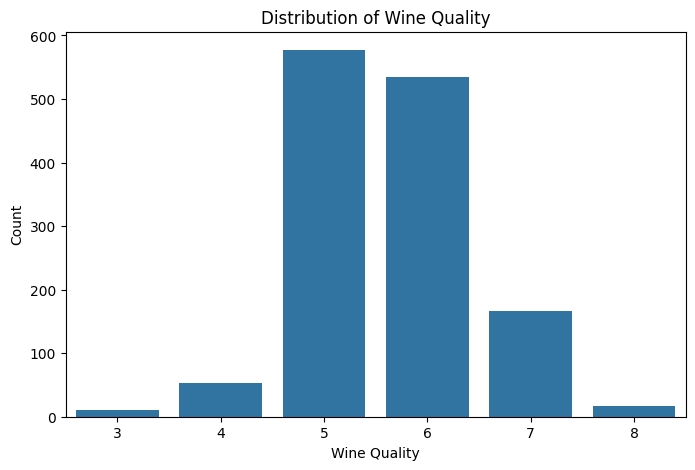

In [11]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='quality')

plt.title('Distribution of Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Count')

plt.show()

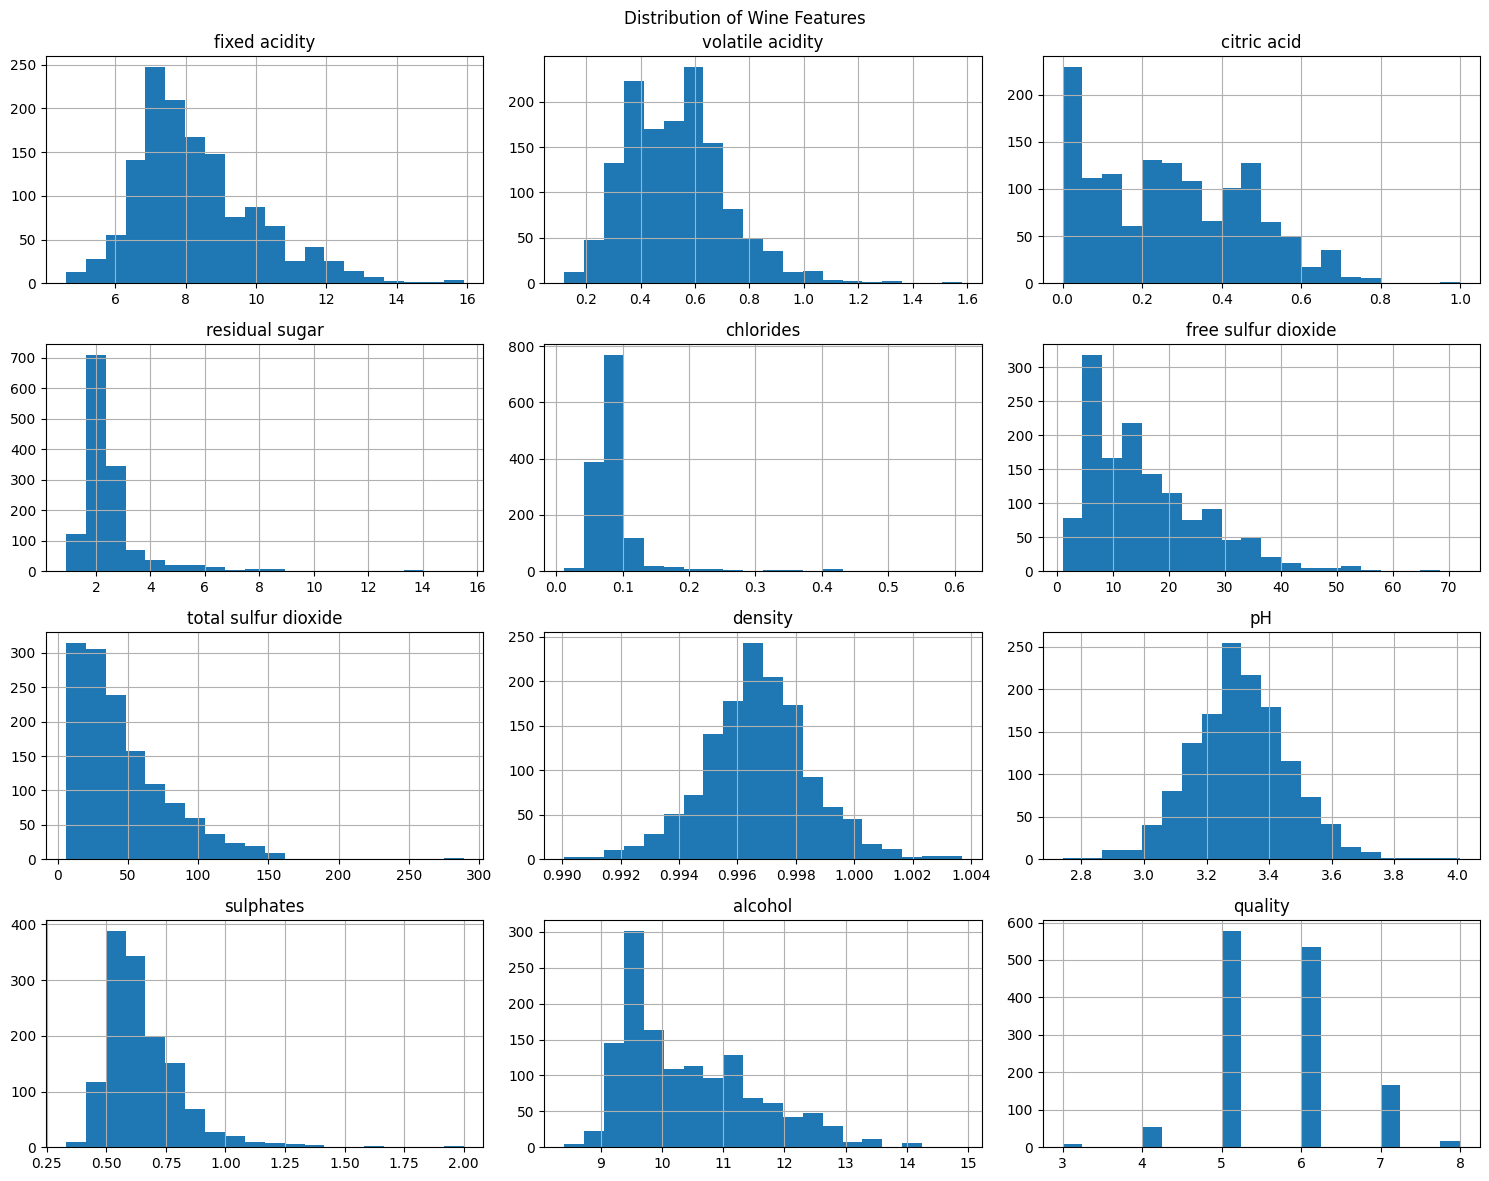

In [12]:
df.hist(figsize=(15,12), bins=20)

plt.suptitle("Distribution of Wine Features")

plt.tight_layout()
plt.show()

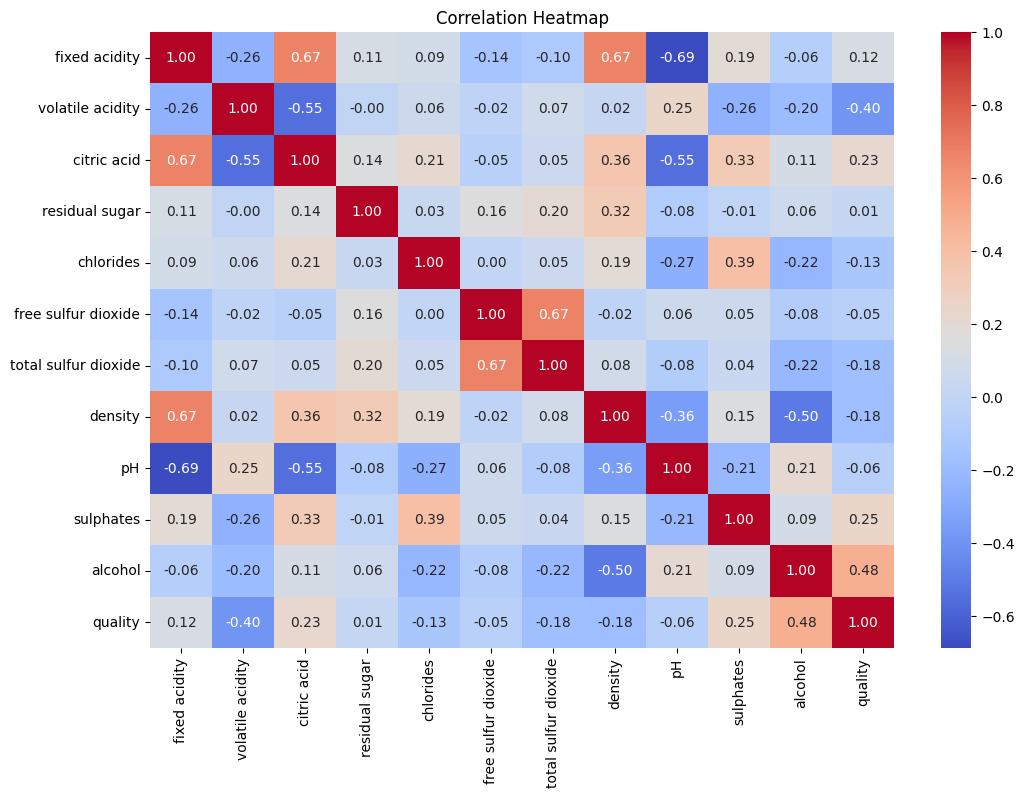

In [13]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

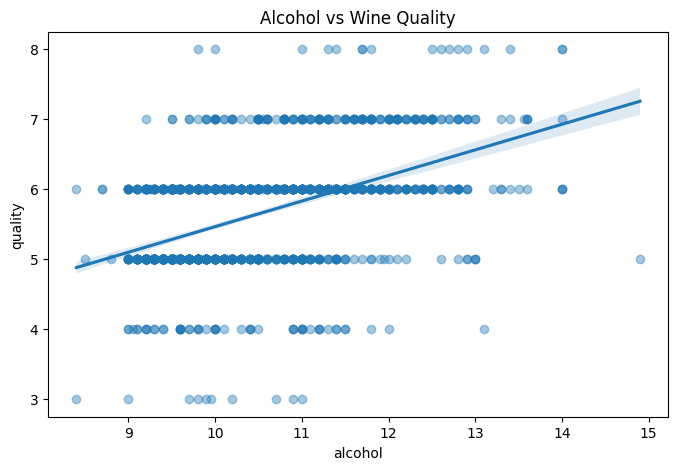

In [14]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x='alcohol',
    y='quality',
    scatter_kws={'alpha':0.4}
)

plt.title('Alcohol vs Wine Quality')
plt.show()

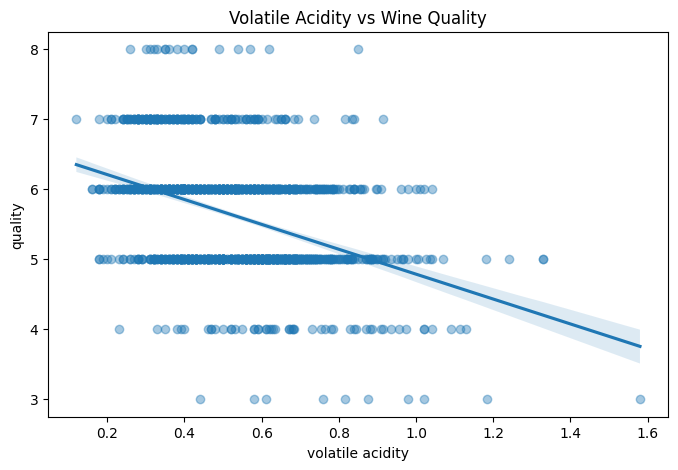

In [15]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x='volatile acidity',
    y='quality',
    scatter_kws={'alpha':0.4}
)

plt.title('Volatile Acidity vs Wine Quality')
plt.show()

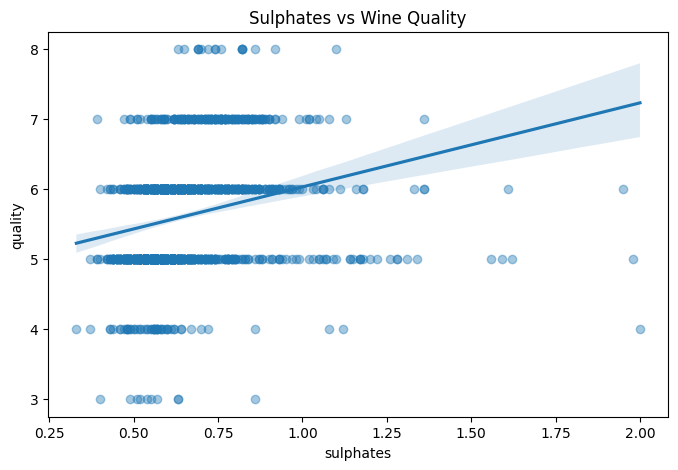

In [16]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x='sulphates',
    y='quality',
    scatter_kws={'alpha':0.4}
)

plt.title('Sulphates vs Wine Quality')
plt.show()

In [17]:
X = df.drop('quality', axis=1)

y = df['quality']

print("Independent variables:", X.shape)
print("Dependent variable:", y.shape)

Independent variables: (1359, 11)
Dependent variable: (1359,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1087, 11)
Testing data: (272, 11)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (1087, 11)
Testing data scaled: (272, 11)


In [20]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [21]:
lr_pred = lr_model.predict(X_test_scaled)

print("First 10 predictions:")
print(lr_pred[:10])

First 10 predictions:
[5.24560141 5.80993501 6.36840525 5.15873325 5.19928608 6.77639051
 5.70671729 4.84475677 5.79995509 5.73940516]


In [22]:
comparison = pd.DataFrame({
    'Actual Quality': y_test.values,
    'Predicted Quality': lr_pred
})

print(comparison.head(10))

   Actual Quality  Predicted Quality
0               5           5.245601
1               6           5.809935
2               7           6.368405
3               5           5.158733
4               4           5.199286
5               7           6.776391
6               5           5.706717
7               5           4.844757
8               6           5.799955
9               5           5.739405


In [23]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate metrics

mae = mean_absolute_error(y_test, lr_pred)

mse = mean_squared_error(y_test, lr_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, lr_pred)

# Display results

print("Linear Regression Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
-------------------------
MAE: 0.5041409053480713
MSE: 0.43100900509009726
RMSE: 0.656512760797608
R2 Score: 0.3915360499058188


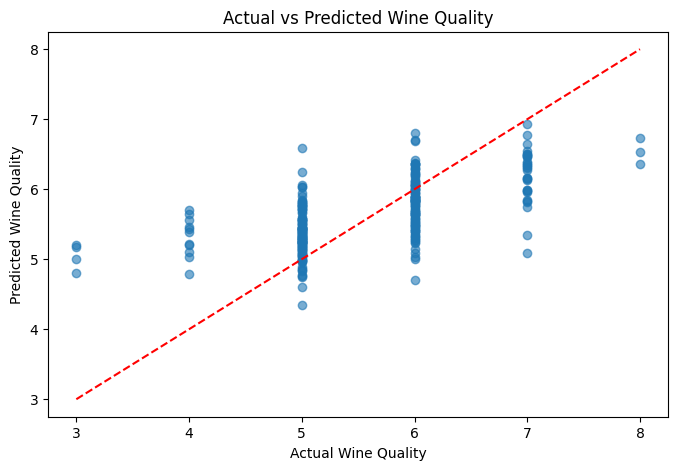

In [24]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, lr_pred, alpha=0.6)

plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")

plt.title("Actual vs Predicted Wine Quality")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()